In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

device = "cuda"
keys = 'u', 'v', 'w', 'p_total'
comp_labels = ['u_x', 'u_y', 'u_z']

def extract(real, keys):
    with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
        data = []
        for k in keys:
            data.append(np.array(f[real][k]))
        return np.stack(data, axis=1)

realizations = ['R13', 'R14', 'R15', 'R18', 'R19', 'R21', 'R22', 'R23', 'R26', 'R28', 'R3', 'R4', 'R5']
samplings = {real: np.s_[:-1:5000 // 300] if real in ["R3", "R4", "R5"] else np.s_[:] for real in realizations}

raw_d = {real: extract(real, keys)[samplings[real]] for real in realizations}
all_data = np.concatenate(list(raw_d.values()), axis=0)

val_realizations = ["R18", "R5"]
test_realizations = ["R3", "R14"]
train_realizations = [real for real in realizations if real not in val_realizations + test_realizations]
val_npds = np.concatenate([raw_d[r] for r in val_realizations])

print("val data shape:", val_npds.shape)

with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
    y = np.array(f["y"])
    x = np.array(f["x"])
    z = np.array(f["z"])

print("y shape:", y.shape)

# ground truth in physical units (shared by all models)
target_phys = val_npds[:, :3, :, :, :].astype(np.float32)
print("target_phys shape:", target_phys.shape)


val data shape: (600, 4, 24, 33, 24)
y shape: (33,)
target_phys shape: (600, 3, 24, 33, 24)


In [6]:
val_npds.nbytes / 2**30 * 600

101.96685791015625

(3900, 4, 24, 33, 24)

In [35]:
from scipy.spatial.distance import pdist, squareform

target = raw_d["R18"]
vels = target[:, :3].reshape(target.shape[0], -1)
vel_dist = squareform(pdist(vels, metric="euclidean"))

In [36]:
pres = target[:, 3].reshape(target.shape[0], -1)
pres_dist = squareform(pdist(pres, metric="euclidean"))

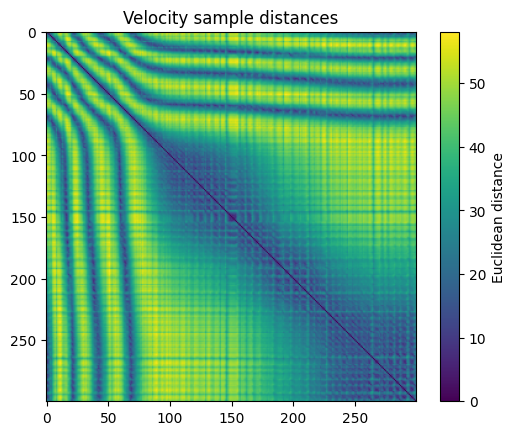

In [37]:
plt.imshow(vel_dist)
plt.title("Velocity sample distances")
plt.colorbar(label="Euclidean distance")
plt.show()

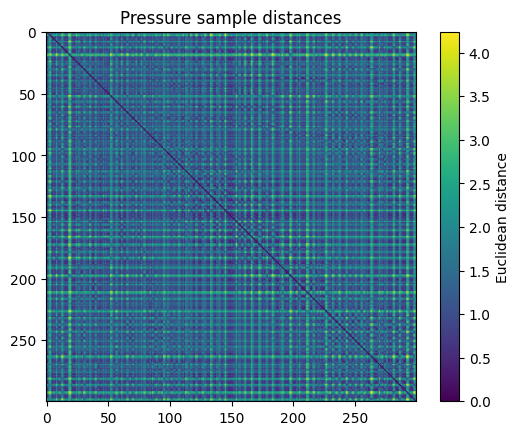

In [38]:
plt.imshow(pres_dist)
plt.title("Pressure sample distances")
plt.colorbar(label="Euclidean distance")
plt.show()

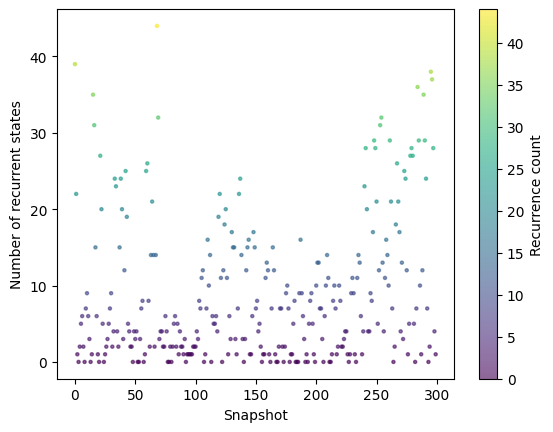

In [55]:
eps = 15
window = 10  # Exclude nearby times

i, j = np.indices(vel_dist.shape)
recurrence = (vel_dist < eps) & (np.abs(i - j) > window)

counts = recurrence.sum(axis=1)

plt.scatter(np.arange(len(counts)), counts, s=5, alpha=0.6, c=counts, cmap="viridis")
plt.colorbar(label="Recurrence count")
plt.xlabel("Snapshot")
plt.ylabel("Number of recurrent states")
plt.show()

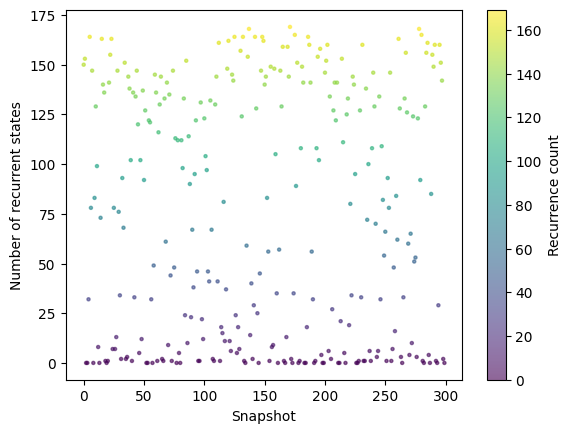

In [57]:
eps = 1
window = 5  # Exclude nearby times

i, j = np.indices(pres_dist.shape)
recurrence = (pres_dist < eps) & (np.abs(i - j) > window)

counts = recurrence.sum(axis=1)

plt.scatter(np.arange(len(counts)), counts, s=5, alpha=0.6, c=counts, cmap="viridis")
plt.colorbar(label="Recurrence count")
plt.xlabel("Snapshot")
plt.ylabel("Number of recurrent states")
plt.show()

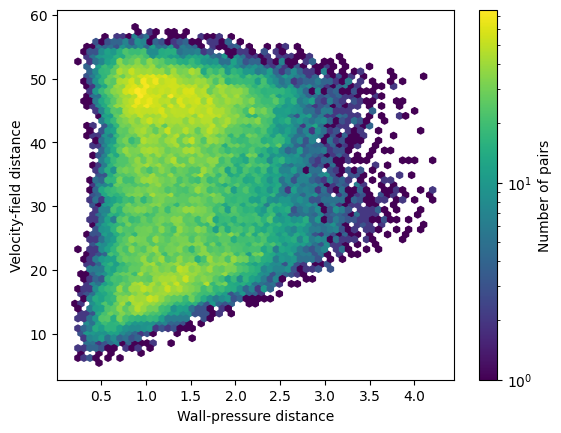

In [59]:
i, j = np.triu_indices(len(pres_dist), k=1)

plt.hexbin(pres_dist[i, j], vel_dist[i, j],
           gridsize=60, bins="log", mincnt=1)
plt.xlabel("Wall-pressure distance")
plt.ylabel("Velocity-field distance")
plt.colorbar(label="Number of pairs")
plt.show()

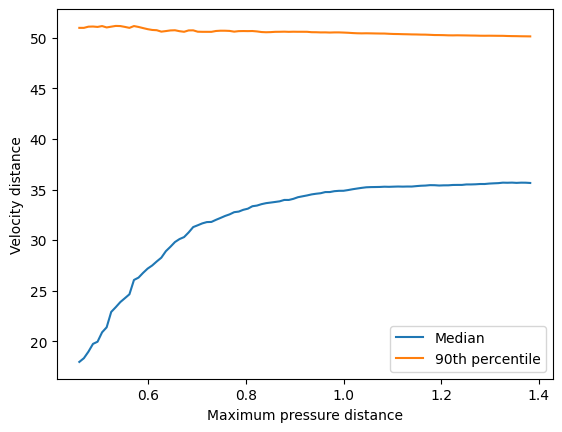

In [62]:
i, j = np.triu_indices(len(pres_dist), k=1)

dp = pres_dist[i, j]
du = vel_dist[i, j]

epsilons = np.linspace(np.percentile(dp, 1), np.percentile(dp, 50), 100)

medians = []
p90 = []

for eps in epsilons:
    selected = du[dp < eps]
    medians.append(np.median(selected))
    p90.append(np.percentile(selected, 90))

plt.plot(epsilons, medians, label="Median")
plt.plot(epsilons, p90, label="90th percentile")
plt.xlabel("Maximum pressure distance")
plt.ylabel("Velocity distance")
plt.legend()
plt.show()